$$\Huge{\text{Motor Vehicle Collisions - Crashes: USA}}$$
[Ver en kaggle](https://www.kaggle.com/datasets/sahityasetu/motor-vehicle-collisions-crashes-usa)

# Estadisitca I

Juan David León Delgado 2211587

Daniel Alejandro Ayala Vallejo 22200484

**Grupo 8**

# Introducción

## Sobre los accidentes en NY

Nueva York es una de las ciudades más densamente pobladas y con mayor tráfico en el mundo, lo que contribuye a una alta incidencia de accidentes de tráfico.

En los últimos años, Nueva York ha visto un aumento significativo en los accidentes de tráfico. Por ejemplo, en 2022, hubo un incremento del 35% en las muertes por accidentes de tráfico en comparación con el año anterior [[1]](https://eldiariony.com/2022/04/12/muertes-por-accidentes-de-transito-en-nueva-york-incrementaron-un-35-en-lo-que-va-de-2022/). Este aumento ha sido motivo de preocupación para las autoridades y ha llevado a la implementación de medidas adicionales de seguridad.

-

## Sobre el dataset

El dataset Motor Vehicle Collisions - Crashes: USA disponible en Kaggle proporciona un registro detallado de los accidentes de tráfico reportados por la policía en la ciudad de Nueva York. Este conjunto de datos es una herramienta valiosa para el análisis estadístico y la investigación en seguridad vial, ya que contiene información exhaustiva sobre cada evento de colisión.

Cada fila del dataset representa un incidente de colisión, documentado a través del formulario MV-104AN, que es obligatorio para accidentes con heridos, fallecidos o daños materiales superiores a $1000. Este formulario recoge datos críticos como la fecha, hora, ubicación, condiciones del accidente y factores contribuyentes.

La recopilación de estos datos comenzó en 1998 con la implementación del programa TrafficStat por parte del Departamento de Policía de Nueva York (NYPD). Este programa se inspiró en el exitoso modelo CompStat, utilizado para mejorar la seguridad pública. En 2014, la iniciativa Vision Zero reforzó la necesidad de una recopilación de datos más detallada con el objetivo de eliminar las muertes por accidentes de tráfico. En 2016, el sistema FORMS reemplazó al anterior sistema TAMS, permitiendo una entrada de datos más eficiente y precisa.

Este dataset no solo permite el análisis de tendencias y patrones en los accidentes de tráfico, sino que también facilita la identificación de áreas problemáticas y la evaluación de la efectividad de las políticas de seguridad vial implementadas.

-

## Sobre el estudio en este informe

Este estudio forma parte del proyecto final para la materia Estadística 1, donde analizamos el conjunto de datos sobre colisiones de vehículos en la ciudad de Nueva York. El objetivo es aplicar técnicas estadísticas para entender mejor los patrones detrás de estos accidentes, como cuándo y dónde ocurren con mayor frecuencia, y qué factores podrían influir en la gravedad de las colisiones.

A través de este análisis, buscamos extraer conclusiones que puedan contribuir a mejorar la seguridad vial en la ciudad. Además, este proyecto nos permitirá practicar y aplicar conceptos estadísticos aprendidos en clase, como el análisis descriptivo y la regresión, para interpretar los datos de manera significativa.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMap
import os
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import norm
import scipy.stats as stats

# Funciones extra

In [ ]:
def graficarHipotesis(alpha, stat):
  # Valores críticos para prueba bilateral
  z_crit = norm.ppf(1 - alpha / 2)

  # Rango para la curva normal estándar
  z_values = np.linspace(-4, 4, 500)
  y_values = norm.pdf(z_values)

  # Gráfica
  plt.figure(figsize=(10, 6))

  # Curva normal estándar
  plt.plot(z_values, y_values, label='Distribución Normal Estándar')

  # Áreas de rechazo
  plt.fill_between(z_values, y_values, where=(z_values <= -z_crit), color='red', alpha=0.3, label='Región de rechazo (izquierda)')
  plt.fill_between(z_values, y_values, where=(z_values >= z_crit), color='red', alpha=0.3, label='Región de rechazo (derecha)')

  # Estadístico z
  plt.axvline(stat, color='blue', linestyle='--', linewidth=2, label=f'Estadístico z = {stat:.2f}')

  # Líneas críticas
  plt.axvline(-z_crit, color='black', linestyle='--', label=f'Valor crítico (-z) = {-z_crit:.2f}')
  plt.axvline(z_crit, color='black', linestyle='--', label=f'Valor crítico (z) = {z_crit:.2f}')

  # Configuración
  plt.title('Prueba de Hipótesis: Estadístico z y Regiones Críticas', fontsize=14)
  plt.xlabel('z', fontsize=12)
  plt.ylabel('Densidad de Probabilidad', fontsize=12)
  plt.legend(fontsize=10)
  plt.grid(alpha=0.3)
  plt.show()

# Cargar el dataframe

In [ ]:
# Revisa si es la primera vez que se conecta el notebook
if "primeraVez" in locals():
  primeraVez = False
else:
  primeraVez = True

# Si es la primera vez, descarga el data set y librerias auxiliares
if primeraVez:
  !pip install gdown
  !pip install --upgrade gdown
  import gdown
  url = "https://drive.google.com/file/d/1Kv9FnudwvNdwVWSVAkHfgXpW0nn1CAoF/view?usp=sharing"
  gdown.download(id=url.split("/")[-2])

# Revisa si ya se cargó el data set en la variable df
if "df" in locals():
  print("Ya tiene cargado el data frame")
  df.info()
else:
  print("No se ha cargado el data frame, cargando...")
  df = pd.read_csv('recipes.csv')

  df.info()

Downloading...
From (original): https://drive.google.com/uc?id=1Kv9FnudwvNdwVWSVAkHfgXpW0nn1CAoF
From (redirected): https://drive.google.com/uc?id=1Kv9FnudwvNdwVWSVAkHfgXpW0nn1CAoF&confirm=t&uuid=9d0f499a-c769-4a81-adc4-4beec274b474
To: /content/MotorVehicleCollisionsNY.csv
100%|██████████| 445M/445M [00:04<00:00, 94.3MB/s]


No se ha cargado el data frame, cargando...


<ipython-input-4-93a2ba80f275>:21: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('MotorVehicleCollisionsNY.csv')


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2102132 entries, 0 to 2102131
Data columns (total 29 columns):
 #   Column                         Dtype  
---  ------                         -----  
 0   CRASH DATE                     object 
 1   CRASH TIME                     object 
 2   BOROUGH                        object 
 3   ZIP CODE                       object 
 4   LATITUDE                       float64
 5   LONGITUDE                      float64
 6   LOCATION                       object 
 7   ON STREET NAME                 object 
 8   CROSS STREET NAME              object 
 9   OFF STREET NAME                object 
 10  NUMBER OF PERSONS INJURED      float64
 11  NUMBER OF PERSONS KILLED       float64
 12  NUMBER OF PEDESTRIANS INJURED  int64  
 13  NUMBER OF PEDESTRIANS KILLED   int64  
 14  NUMBER OF CYCLIST INJURED      int64  
 15  NUMBER OF CYCLIST KILLED       int64  
 16  NUMBER OF MOTORIST INJURED     int64  
 17  NUMBER OF MOTORIST KILLED      int64  
 18  CO

# Limpieza del dataframe
(Bastante complicado limpiar +1M de datos)

In [ ]:
# Eliminar colummnas no necesarias y en las que predomina NAN
dfClear = df.drop(columns=['ZIP CODE', 'BOROUGH', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3',
                            'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'COLLISION_ID', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5'])

# Eliminar todas las filas NAN
dfClear = dfClear.dropna()

dfClear = dfClear[dfClear["NUMBER OF PERSONS INJURED"] >= 0]
dfClear = dfClear[dfClear["CONTRIBUTING FACTOR VEHICLE 1"] != "Unspecified"]

# Renombrar todas las columnas
dfClear = dfClear.rename(columns={'CRASH DATE':'Fecha', 'CRASH TIME':'Hora', 'LATITUDE':'Latitud', 'LONGITUDE':'Longitud',
                                  'NUMBER OF PERSONS INJURED':'Personas heridas', 'NUMBER OF PERSONS KILLED':'Personas fallecidas',
                                  'NUMBER OF PEDESTRIANS INJURED':'Peatones heridos', 'NUMBER OF PEDESTRIANS KILLED':'Peatones fallecidos',
                                  'NUMBER OF CYCLIST INJURED':'Ciclistas heridos', 'NUMBER OF CYCLIST KILLED':'Ciclistas fallecidos',
                                  'NUMBER OF MOTORIST INJURED':'Motociclistas heridos', 'NUMBER OF MOTORIST KILLED':'Motociclistas fallecidos',
                                  'CONTRIBUTING FACTOR VEHICLE 1':'Causa accidente', 'VEHICLE TYPE CODE 1':'Tipo vehículo'})

# Redondear los valores numericos a int
dfClear['Personas heridas'] = dfClear['Personas heridas'].round(0).astype(int)
dfClear['Personas fallecidas'] = dfClear['Personas fallecidas'].round(0).astype(int)

# Pasa las fechas de String a datetime object
dfClear['Fecha'] = pd.to_datetime(dfClear['Fecha'], format = '%m/%d/%Y')

# Reinicia los indices en cada fila
dfClear = dfClear.reset_index(drop=True)
dfClear.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1224396 entries, 0 to 1224395
Data columns (total 14 columns):
 #   Column                    Non-Null Count    Dtype         
---  ------                    --------------    -----         
 0   Fecha                     1224396 non-null  datetime64[ns]
 1   Hora                      1224396 non-null  object        
 2   Latitud                   1224396 non-null  float64       
 3   Longitud                  1224396 non-null  float64       
 4   Personas heridas          1224396 non-null  int64         
 5   Personas fallecidas       1224396 non-null  int64         
 6   Peatones heridos          1224396 non-null  int64         
 7   Peatones fallecidos       1224396 non-null  int64         
 8   Ciclistas heridos         1224396 non-null  int64         
 9   Ciclistas fallecidos      1224396 non-null  int64         
 10  Motociclistas heridos     1224396 non-null  int64         
 11  Motociclistas fallecidos  1224396 non-null  int64 

In [ ]:
#Eliminar causas de accidentes repetidas o parecida:

# Convertir todo a minúsculas para evitar duplicados por mayúsculas/minúsculas
dfClear['Causa accidente'] = dfClear['Causa accidente'].str.lower()

# Reemplazar errores tipográficos
dfClear['Causa accidente'] = dfClear['Causa accidente'].replace({
    'illnes':'illness'})

# Eliminar datos que no coinciden con las causas reales
dfClear = dfClear[~dfClear['Causa accidente'].isin(['80', '1'])]


causas_accidentes = {
    # Categorías relacionadas con la operación incorrecta del vehículo
    "falla_mecánica": [
        "falla_mecánica", "steering failure", "brakes defective", "accelerator defective",
        "tire failure/inadequate", "headlights defective", "tow hitch defective",
        "windshield inadequate", "vehicle vandalism", "lane marking improper/inadequate",
        "pavement defective", "other lighting defects", "shoulders defective/improper"
    ],
    "error_humano": [
        "error_humano", "passing too closely", "passing or lane usage improper",
        "turning improperly", "unsafe speed", "following too closely",
        "failure to yield right-of-way", "backing unsafely",
        "failure to keep right", "traffic control disregarded",
        "unsafe lane changing", "driver inexperience",
        "driverless/runaway vehicle", "reaction to other uninvolved vehicle",
        "reaction to uninvolved vehicle", "aggressive driving/road rage"
    ],
    "distracciones": [
        "distracciones", "driver inattention/distraction", "passenger distraction",
        "eating or drinking", "cell phone (hands-free)",
        "cell phone (hand-held)", "using on board navigation device",
        "listening/using headphones", "other electronic device",
        "texting", "outside car distraction"
    ],
    "condiciones_físicas_del_conductor": [
        "condiciones_físicas_del_conductor", "fatigued/drowsy", "fell asleep", "lost consciousness",
        "illness", "physical disability", "prescription medication"
    ],
    "uso_de_sustancias": [
        "uso_de_sustancias", "alcohol involvement", "drugs (illegal)"
    ],
    "condiciones_del_entorno": [
        "condiciones_del_entorno", "pavement slippery", "obstruction/debris", "animals action",
        "tinted windows", "glare", "view obstructed/limited"
    ],
    "uso_indebido_del_vehículo": [
        "uso_indebido_del_vehículo", "oversized vehicle", "driverless/runaway vehicle",
        "vehicle vandalism"
    ],
    "fallos_en_el_entorno_vial": [
        "fallos_en_el_entorno_vial", "traffic control device improper/non-working",
        "traffic control disregarded", "lane marking improper/inadequate"
    ],
    "otros": [
        "otros", "pedestrian/bicyclist/other pedestrian error/confusion"
    ]
}

# Función para mapear y limpiar los valores
def limpiar_tipo_vehiculo(valor):
    if not isinstance(valor, str) or valor.strip() == '':
        return np.nan
    valor = valor.lower().strip()
    # Buscar en causas_accidentes
    for categoria, palabras_clave in causas_accidentes.items():
        if valor in palabras_clave:
            return categoria
    # Retornar el valor original si no se encuentra en las causas_accidentes
    return categoria

# Aplicar la limpieza
dfClear["Causa accidente"] = dfClear["Causa accidente"].apply(limpiar_tipo_vehiculo)


print(dfClear["Causa accidente"].unique())
#print(len(dfClear[dfClear["Causa accidente"] == 'distracciones']))

['error_humano' 'falla_mecánica' 'otros' 'distracciones'
 'uso_indebido_del_vehículo' 'uso_de_sustancias' 'condiciones_del_entorno'
 'condiciones_físicas_del_conductor' 'fallos_en_el_entorno_vial']


In [ ]:
# Convertir todo a minúsculas para evitar duplicados por mayúsculas/minúsculas
dfClear['Tipo vehículo'] = dfClear['Tipo vehículo'].str.lower()

agrupaciones = {
    'sedan': ['sedan', '4 dr sedan', '2 dr sedan', 'car/suv', 'passenger vehicle', '2 dr', '4door', '4dsd', 'sudn', 'vagon', '4ds', '4d', 'ford', 'dodge', '4 run', 'nissa', 'toyota', 'chevrolet', 'sedona', 'fusion', 'car carrie', 'camry'],
    'suv': ['station wagon/sport utility vehicle', 'suv', 'sport utility / station wagon', 'suburban', 'subn/van', 'subn', 'subur', 'r/v', 'r/v c', 'honda hrv', 'jeep', '4 whee', 'humvee', 'honda hrv'],
    'pickup': ['pick-up truck', 'pickup', 'pick-up', 'pick up', 'pick up tr', 'pk', 'picku', 'pick wh', 'pkup', 'pick-', 'pickup tru', 'pickup with mounted camper', 'pick-up tr', 'pick', 'govt p/u t', 'pickup tow', 'dodge ram', 'ford f150', 'ford f-150', 'ram promas', 'f550', 'f650', 'dodge'],
    'truck': ['box truck', 'dump truck', 'flat bed', 'tow truck', 'tow truck / wrecker', 'tractor truck diesel',
              'tractor truck gasoline', 'dump', 'garbage truck', 'van/truck', 'truck', 'delivery truck',
              'freight truck', 'semi truck', 'semi trail', 'tanker', 'armored truck', 'u-haul truck', 'boxtruck',
              'tow-truck', 'work truck', 'fire truck', 'cement truck', 'garbage or refuse', 'beverage truck', 'usps truck', 'chassis cab', 'flat rack',
              'bulk agriculture', 'concrete mixer', 'open body', 'glass rack', 'mack', 'carrier', 'usps', 'department', 'pallet', 'refrigerated van', 'mailtruck',
              'tank', 'stake or rack', 'pick up tr', 'con ed tru', 'firetruck', 'sanmen cou', 'pump', 'multi-wheeled vehicle', 'utility', 'livestock rack', 'cement tru', 'delivery t', 'mack truck',
              'fdny truck', 'garbage tr', 'semi', 'u-haul tru', 'fedex truc', 'dumptruck', 'tow', 'tractor tr', 'freight', 'tow t', 'towtr', 'dump', 'freight va', 'utility truck', 'dot truck', 'mta truck', 'commercial', 'unk box tr', 'tr', 'utility tr', 'truck/van', 'freight tr', 'tractor', 'ups truck', 'truck flat', 'truck cran', 'heavy truc', '18 wheeler', '18 wh', 'box t', 'truck trai', 'truck'],
    'motorcycle': ['motorcycle', 'motorbike', 'dirt bike', 'minibike', 'e motorcyc', 'moped', 'moped 150c', 'motorscooter', 'minicycle', 'motorscoot', 'motor scoo', 'gas mo ped', 'mopad', 'mo pe', 'mopped',
                   'electric m', 'motor', 'mcy', 'moped scoo', 'boom moped', 'mo-ped', 'mopd', 'electric motorc', 'yamaha', 'scooter', 'gas moped', 'lime mope', 'revel', 'e revel sc', 'flywing mo', 'razor150 m', 'e-skateboa', 'dirtb', 'scooter', 'one wheel]'],
    'bicycle': ['pedic', 'food cart', 'bike', 'bicycle', 'ebike', 'e-bike', 'electric bike', 'e bike uni', 'pedicab', 'e bike', 'e-bik', 'electric b', 'bicyc', 'e bik'],
    'bus': ['bus', 'school bu', 'charter bu', 'mta b', 'mini schoo', 'postal bus', 'nyu s', 'omnibus', 'bus', 'school bus', 'charter bus', 'mta bus', 'shuttle bus', 'shuttle bu', 'mini bus', 'schoolbus', 'charter bu', 'city bus', 'yellow bus', 'small bus', 'nyc bus', 'nj transit', 'mta', 'livery bus'],
    'van': ['van', 'van wh', 'mini vahn', 'sprinter w', 'ford trans', 'vanette', 'pro master', 'van/b', 'marked van', 'us postal', 'ups m', 'livery vehicle', 'van', 'minivan', 'mini van', 'work van', 'refrigerated van', 'van truck', 'sprinter', 'cargo van', 'lunch wagon', 'carry all', 'ford van', 'nypd van', 'van camper', 'rv', 'sprinter v', 'white van',
            'verzion va', 'transit van', 'cargo', 'mta van', 'pass van', 'transit va', 'freigt van', 'freight va', 'van t', 'econoline', 'moving van', 'econo', 'van/t', 'miniv', 'mini vahn', 'deliv wh'],
    'ambulance': ['�mbu', 'ambulance', 'fdny ambul', 'ambulanve', 'fdny ems#1', 'ems fdny b', 'g amb', 'ambulance', 'fdny ambul', 'ambulette', 'ambu', 'fdny ems', 'ems truck', 'ems bus', 'émbu', 'ambulace', 'ambulane', 'amb', 'nys ambula', 'amubulance', 'ambulence', 'ems ambula', 'ambulance',
                  'nyc ambula', 'fdny emt', 'gen  ambul', 'emt ambula', 'emergency'],
    'scooter': ['scooter', 'lime scoot', 'manual sco', 'e-skateboa', 'gas moped', 'electric moped', 'razor scoo', 'e-scooter', 'escooter', 'kick scooter', 'scooter', 'e scooter', 'gas scoote', 'motor scoo', 'kick scoot', '50cc scoot', 'escooter s', 'scoot', 'e-sco', 'scooter ga', 'motor skat',
                'push scoot', 'e sco', 'manual sco', 'stand up s', 'lime scoot', 'razor scoo', 'e. scoot'],
    'taxi': ['tlc', 'marked van', 'taxi', 'yellow tax', 'yellow cab'],
    'car': ['convertible', '3-door', 'motor home', 'motorhome', 'car c', 'smart car', 'smart'],
    'unknown': ['unknown', 'unk', 'psd', 'self', 'postal ser', 'ems bus', 'self insur', 'tcn', 'tf', 'commercial', 'city owned', 'unmarked v', 'city', 'post offic', '994', 'esu rep', 'pc', 'com', 'm2', 'locomotive',
                'hwh', 'vms', 'other', 'oth', 'na', 'unknown ve', 'unkno', 'unkown', 'ukn'],
    'lift equipment': ['lift boom', 'forklift', 'hopper', 'pump', 'lift', 'cat forkli', 'fork lift', 'forkl', 'fork', 'fork-', 'yale fork', 'boom lift'],
    'specialized vehicles': ['excavator', 'street swe', 'golf cart', 'firetruck', 'road sweep', 'street cle', 'fire appar', 'asphalt ro', 'snow plow', 'horse trai', 'fire', 'fire engin', 'fdny fire', 'power shov', 'grumman ll',
                              'cmix', 'utility ve', 'crane boom', 'skateboard', 'motorized', 'ram', 'tlr', 'moving tru', 'delv', 'nyc sanita', 'golf', 'snowplow', 'plow', 'sweeper', 'snow', 'swepe', 'street', 'stree', 'sweeper tr'],
    'trailer': ['trailer', 'semi-trail', 'semi trailer', 'tr-trailer', 'ttrailer', 'trail', 'trlr', 'comm trail', 'trailer ca', 'comm'],
    'limo': ['limo', 'limou'],
    'fdny': ['fdny firet', 'fdny', 'fdny ladde', 'fdny engin', 'fdny chief', 'fdny fire', 'nyfd', 'fdny- fire', 'fdny utili', 'fdny vehic', 'fdny ems#1', 'fdny 245 e', 'fdny ems v', 'fdny mecha'],
    'passenger': ['12 passage', 'passenger', 'passe', 'passanger', '12 pa', '15 pa', '10 paaseng'],
    'delivery': ['delivery', 'delivery truck', 'delv', 'deliv', 'del', 'delivery v', 'com delive', 'delivery t', 'comm delivery', 'delvi', 'det truck', 'del truck'],
    'usps': ['usps mail', 'usps posta', 'usps van', 'mail truck', 'mail', 'u.s. posta', 'usps #7530', 'us po', 'us mail #1', 'u.s. mail', 'postal tru', 'usps  van', 'postal ser', 'mail carri', 'usps vehic'],
    'police': ['police rep', 'nypd', 'nypd traff', 'nypd tow t'],
    'electric': ['electric s', 'electric', 'electric c', 'electric m', 'electric b', 'electric bike', 'electric bike', 'electric motorc', 'ele. unicy', 'ele motorc', 'ele tow'],
    'construction': ['constructi', 'const', 'construction', 'heavy', 'construction vehicle'],
    'farm': ['farm vehicle', 'john deere'],
    'military': ['military', 'humvee', 'army'],
    'commercial': ['commercial vehicle', 'commer veh', 'large com veh(6 or more tires)', 'small com veh(4 tires)', 'comm', 'comm.', 'comme', 'commm', 'commerical', 'commercial', 'comm trans', 'commercial']
}

# Función para mapear y limpiar los valores
def limpiar_tipo_vehiculo(valor):
    if not isinstance(valor, str) or valor.strip() == '':
        return np.nan
    valor = valor.lower().strip()
    # Buscar en agrupaciones
    for categoria, palabras_clave in agrupaciones.items():
        if valor in palabras_clave:
            return categoria
    # Retornar el valor original si no se encuentra en las agrupaciones
    return 'unknown'

# Aplicar la limpieza
dfClear["Tipo vehículo"] = dfClear["Tipo vehículo"].apply(limpiar_tipo_vehiculo)

print(dfClear["Tipo vehículo"].unique())

# print(len(dfClear[dfClear["Tipo vehículo"] == 'unknown']))
# dfClear[dfClear['Tipo vehículo'] == 'unknown'].count()

['sedan' 'suv' 'truck' 'bus' 'taxi' 'van' 'bicycle' 'ambulance'
 'motorcycle' 'scooter' 'pickup' 'lift equipment' 'unknown' 'car'
 'specialized vehicles' 'trailer' 'limo' 'fdny' 'passenger' 'electric'
 'delivery' 'usps' 'police' 'construction' 'commercial' 'farm' 'military']


In [ ]:
dfClear = dfClear.sort_values(by='Fecha')
dfClear = dfClear.reset_index(drop=True)

# Convertir la columna Hora en solo horas (sin los minutos)
dfClear['Hora'] = pd.to_datetime(dfClear['Hora'], format='%H:%M').dt.hour

dfPorYear = {
    '2014': dfClear[(dfClear['Fecha'] >= '2014-01-01') & (dfClear['Fecha'] <= '2014-12-31')].reset_index(drop=True),
    '2015': dfClear[(dfClear['Fecha'] >= '2015-01-01') & (dfClear['Fecha'] <= '2015-12-31')].reset_index(drop=True),
    '2016': dfClear[(dfClear['Fecha'] >= '2016-01-01') & (dfClear['Fecha'] <= '2016-12-31')].reset_index(drop=True),
    '2017': dfClear[(dfClear['Fecha'] >= '2017-01-01') & (dfClear['Fecha'] <= '2017-12-31')].reset_index(drop=True),
    '2018': dfClear[(dfClear['Fecha'] >= '2018-01-01') & (dfClear['Fecha'] <= '2018-12-31')].reset_index(drop=True),
    '2019': dfClear[(dfClear['Fecha'] >= '2019-01-01') & (dfClear['Fecha'] <= '2019-12-31')].reset_index(drop=True),
    '2020': dfClear[(dfClear['Fecha'] >= '2020-01-01') & (dfClear['Fecha'] <= '2020-12-31')].reset_index(drop=True),
    '2021': dfClear[(dfClear['Fecha'] >= '2021-01-01') & (dfClear['Fecha'] <= '2021-12-31')].reset_index(drop=True),
    '2022': dfClear[(dfClear['Fecha'] >= '2022-01-01') & (dfClear['Fecha'] <= '2022-12-31')].reset_index(drop=True),
    '2023': dfClear[(dfClear['Fecha'] >= '2023-01-01') & (dfClear['Fecha'] <= '2023-12-31')].reset_index(drop=True),
    '2024': dfClear[(dfClear['Fecha'] >= '2024-01-01') & (dfClear['Fecha'] <= '2024-12-31')].reset_index(drop=True),
}

dfPorYear['2014']

,Fecha,Hora,Latitud,Longitud,Personas heridas,Personas fallecidas,Peatones heridos,Peatones fallecidos,Ciclistas heridos,Ciclistas fallecidos,Motociclistas heridos,Motociclistas fallecidos,Causa accidente,Tipo vehículo
0,2014-01-01,12,40.703577,-73.809695,0,0,0,0,0,0,0,0,otros,sedan
1,2014-01-01,13,40.765320,-73.889040,0,0,0,0,0,0,0,0,condiciones_físicas_del_conductor,unknown
2,2014-01-01,3,40.858709,-73.903691,0,0,0,0,0,0,0,0,otros,sedan
3,2014-01-01,2,40.791570,-73.944677,0,0,0,0,0,0,0,0,condiciones_físicas_del_conductor,sedan
4,2014-01-01,16,40.736005,-73.993617,1,0,1,0,0,0,0,0,error_humano,taxi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80529,2014-12-31,23,40.754619,-73.973734,0,0,0,0,0,0,0,0,error_humano,sedan
80530,2014-12-31,16,40.860521,-73.892565,1,0,1,0,0,0,0,0,error_humano,unknown
80531,2014-12-31,13,40.726295,-73.846185,0,0,0,0,0,0,0,0,error_humano,suv
80532,2014-12-31,20,40.766779,-73.996762,0,0,0,0,0,0,0,0,condiciones_físicas_del_conductor,van


# Gráficos

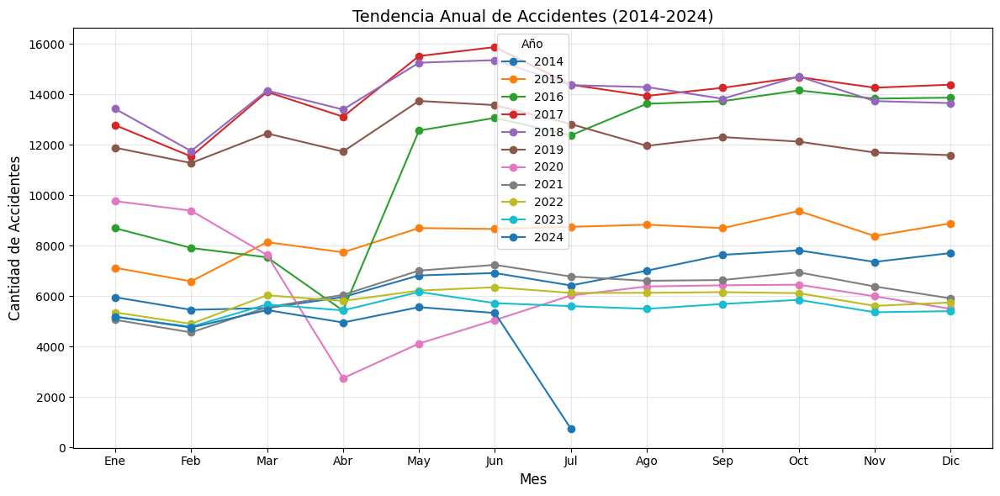

In [ ]:
# Crear un DataFrame vacío para almacenar los resultados agrupados
tendencia_anual = pd.DataFrame()

# Iterar sobre los años en dfPorYear
for year, df in dfPorYear.items():
    # Agrupar los datos por mes y contar el número de accidentes
    accidentes_por_mes = df.groupby(df['Fecha'].dt.month).size()
    # Agregar al DataFrame con el año como columna
    tendencia_anual[year] = accidentes_por_mes

# Ajustar los índices para representar los meses
tendencia_anual.index = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

# Graficar la tendencia anual
plt.figure(figsize=(12, 6))
for year in tendencia_anual.columns:
    plt.plot(tendencia_anual.index, tendencia_anual[year], marker='o', label=year)

# Configurar el gráfico
plt.title('Tendencia Anual de Accidentes (2014-2024)', fontsize=14)
plt.xlabel('Mes', fontsize=12)
plt.ylabel('Cantidad de Accidentes', fontsize=12)
plt.legend(title='Año', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

En esta grafica podemos observar cómo se han comportado los accidentes automovilísticos en New York desde el 2014 hasta Julio del 2024, con una distribución mensual y anual. Al analizar los datos podemos notar distintas tendencias de gran importancia
1.	Comportamiento normal antes de 2020:
Entre 2014 y 2019, los accidentes son estables, con pequeños aumentos en algunos años. Esto nos indica que en esos años no hubo grandes cambios en la manera en que las personas se movilizaban.
2.	La caída en 2020 por la pandemia:
A partir de 2020, hay una caída muy notable en los accidentes. Podemos deducir que este gran cambio en la tendencia de los accidentes fue causado por la pandemia del Covid-19, esto por varios factores claves, como lo son:
*	Imposición de Cuarentena en la ciudad, debido a esto los accidentes cayeron enormemente, ya que al estar en cuarentena las personas no salían tanto a la calle.
*	El trabajo remoto se popularizó, haciendo que muchos ya no tuvieran que ir al trabajo de forma presencial, disminuyendo el uso de vehículos.
*	Se suspendieron eventos sociales y viajes, lo que también bajó la cantidad de autos en las calles.
Menos tráfico claramente significó menos accidentes.
3.	Recuperación a partir de 2021:
Después de 2020, con el levantamiento de muchas restricciones, los accidentes empiezan a subir otra vez. Sin embargo, algo interesante es que en 2023 y 2024 los niveles no han vuelto al punto donde estaban antes de la pandemia. Esto podría deberse a:
*	Cambios en los hábitos de movilidad, como que más gente sigue trabajando desde casa.
*	Un mayor uso de medios de transporte alternativos, como bicicletas o scooters eléctricos, que se hicieron populares en la ciudad.
* Uso de aplicaciones para pedir productos, al no salir la gente para comprar cosas, si no que  las piden en linea hay una disminución en la densidad vehicular de la ciudad
4.	Tendencias mensuales:
También se puede ver que ciertos meses tienen más accidentes que otros. Por ejemplo, durante el invierno (enero y febrero), las condiciones climáticas como la nieve o la lluvia son causantes de mayores accidentes. Algo que resalta en 2020 es que los accidentes bajaron muchísimo en junio y julio, coincidiendo con los meses de restricciones más fuertes por el COVID.
5.	Conclusión:
En general, esta gráfica no solo muestra cómo han cambiado los accidentes a lo largo del tiempo, sino también cómo un evento global como la pandemia tuvo un impacto directo en el comportamiento de los accidentes

<Figure size 1200x600 with 0 Axes>

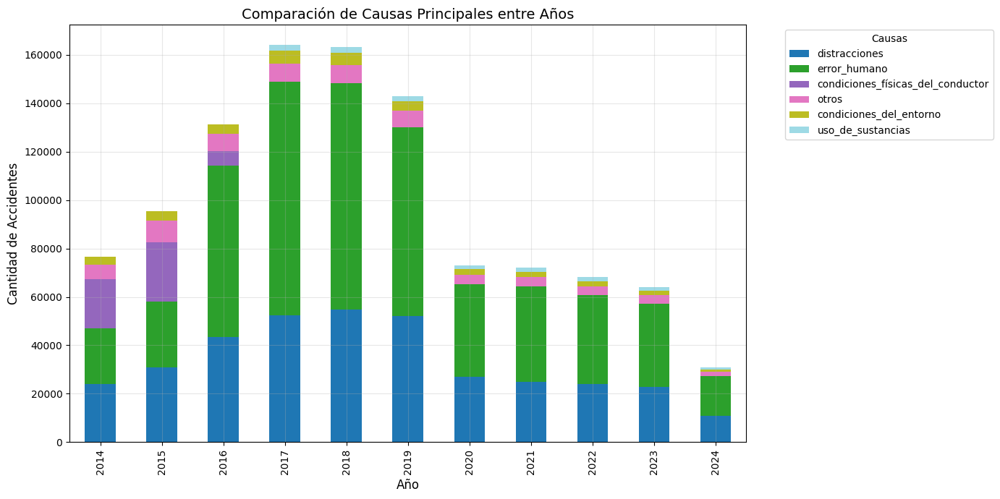

In [ ]:
# Definir el número de causas principales a analizar
top_n_causas = 5

# Crear un DataFrame vacío para almacenar las frecuencias por causa y año
causas_comparacion = pd.DataFrame()

# Iterar sobre cada año en dfPorYear
for year, df in dfPorYear.items():
    # Contar las ocurrencias de cada causa en el año
    causas_frecuencia = df['Causa accidente'].value_counts()
    # Tomar las 'top_n_causas' más comunes
    top_causas = causas_frecuencia.nlargest(top_n_causas)

    # Agregar al DataFrame
    for causa in top_causas.index:
        if causa not in causas_comparacion.index:
            causas_comparacion.loc[causa, year] = top_causas[causa]
        else:
            causas_comparacion.loc[causa, year] = top_causas[causa]

# Rellenar valores faltantes con 0
causas_comparacion = causas_comparacion.fillna(0)

# Transponer para facilitar el gráfico
causas_comparacion_t = causas_comparacion.T


# Crear el gráfico
plt.figure(figsize=(12, 6))
causas_comparacion_t.plot(kind='bar', stacked=True, figsize=(14, 7), colormap='tab20')

# Configuración del gráfico
plt.title('Comparación de Causas Principales entre Años', fontsize=14)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Cantidad de Accidentes', fontsize=12)
plt.legend(title='Causas', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

En esta grafica podemos ver cuales son las principales causas de accidentes automovilísticos en la ciudad de New York, en este diagrama de barras podemos ver dichas causas de los accidentes que son distracciones, error humano, condiciones físicas del conductor, uso de sustancias, condiciones del entorno, entre otras.

1.	El error humano como la mayor causa de accidentes:
Desde 2014 hasta 2024, el "error humano" (representado en verde) destaca como la principal causa de accidentes. Gracias a esto sabemos que los errores humanos son un importante objetivo para la reducción de accidentes, así que nuevas tecnologías como la conducción automática de Tesla podrían ayudar en enorme medida a evitar los accidentes
2.	Distracciones en segundo lugar:
Las distracciones (en azul) son otra causa importante y consistentemente relevante. Con esto seguimos viendo que la causa humana es la que crea estos accidentes, por lo tanto una tecnología que ayude a corregir los errores humanos puede significar un gran cambio en los accidentes que ocurren diariamente.
3.	Impacto de la pandemia en 2020:
Al igual que en el análisis anterior, 2020 es un punto clave. Se observa una reducción general en todas las causas de accidentes, pero esto no necesariamente significa que se resolvieron los problemas de fondo, sino que la disminución del tráfico (por cuarentenas y restricciones) redujo la exposición a los accidentes.

4.	Causas menos comunes pero importantes:
*	Condiciones físicas del conductor (rosa): Incluye factores como cansancio o problemas de salud. Aunque no es la principal causa, tiene un impacto constante.
*	Uso de sustancias (celeste): Aunque es la categoría menos representada, sigue siendo preocupante, especialmente porque implica decisiones conscientes del conductor.
*	Condiciones del entorno (amarillo): Factores como el clima o el estado de las vías son menos frecuentes, pero pueden ser cruciales en ciertas épocas del año o en regiones específicas.

5.	Tendencias después de la pandemia:
Después de 2020, los accidentes vuelven a aumentar, pero no alcanzan los niveles de 2019. Esto puede deberse a una combinación de factores:
*	Nuevas políticas de movilidad o mejoras en la infraestructura vial.
*	Menor densidad de tráfico en comparación con los años prepandemia
6.	Conclusión:
Este análisis nos ayuda a ver que, aunque las causas varían en impacto, el error humano y las distracciones son problemas constantes. Para reducir los accidentes, sería clave implementar más educación vial, mejorar las leyes de tránsito y seguir innovando en tecnologías que ayuden a los conductores a prevenir errores.


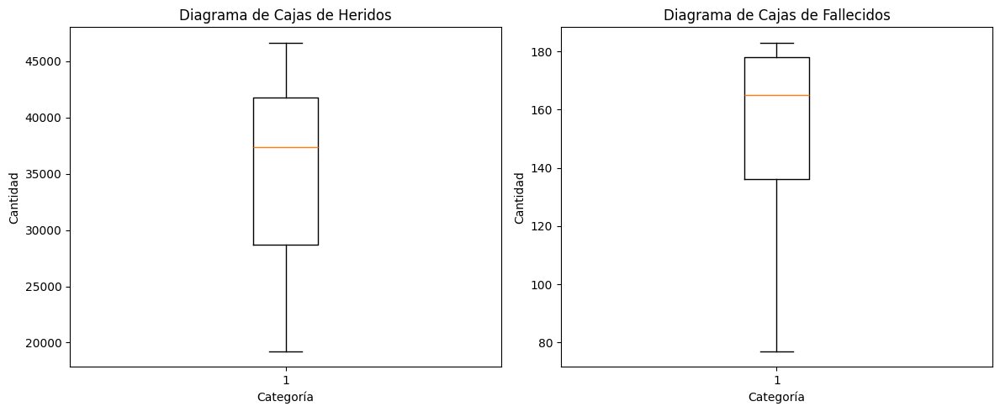

In [ ]:
# Crear un DataFrame vacío para almacenar los resultados agrupados
dfSeveridad = pd.DataFrame(columns=['año', 'heridos', 'fallecidos'])

# Iterar sobre cada año en dfPorYear
for year, df in dfPorYear.items():
    # Contar las ocurrencias de cada causa en el año
    heridos = df['Personas heridas'].sum()
    fallecidos = df['Personas fallecidas'].sum()
    # Agregar al DataFrame
    dfSeveridad.loc[len(dfSeveridad)] = [year, heridos, fallecidos]

# Crear el subplot
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Diagrama de cajas de Heridos
axs[0].boxplot(dfSeveridad['heridos'])
axs[0].set_title('Diagrama de Cajas de Heridos')
axs[0].set_xlabel('Categoría')
axs[0].set_ylabel('Cantidad')

# Subplot 2: Diagrama de cajas de Fallecidos
axs[1].boxplot(dfSeveridad['fallecidos'])
axs[1].set_title('Diagrama de Cajas de Fallecidos')
axs[1].set_xlabel('Categoría')
axs[1].set_ylabel('Cantidad')

# Ajustar el layout
plt.tight_layout()
plt.show()

En esta gráfica comparamos dos diagramas de cajas y bigotes: uno para la cantidad de heridos y otro para los fallecidos en accidentes automovilísticos en New York. Este tipo de gráfico nos permite observar la distribución de los datos de manera rápida. A continuación, presentaremos un análisis de cada gráfica y compararemos las mismas.

1. Diagrama de Cajas de Heridos
*	Rango intercuartil (IQR):
La mayoría de los datos (entre el primer y tercer cuartil) se pueden observar entre 30,000 y 42,000 heridos. Esto indica que, aunque hay cierta variabilidad, la cantidad de heridos suele mantenerse dentro de este rango.
*	Mediana:
La línea naranja en el centro del diagrama indica que la mediana está alrededor de 37,000 heridos.
*	Bigotes:
  *	El bigote inferior llega a 20,000 heridos, lo que nos dice que este es el menor valor dentro del rango esperado.
  *	El bigote superior alcanza los 45,000 heridos, lo que nos dice que este es el valor más alto del rango esperado.
  * Estos valores nos muestran que los datos están bastante dispersos unos de otros en comparación a la cantidad de muertos
*	Interpretación:
La cantidad de heridos en accidentes presenta cierta variabilidad, pero los datos parecen estar en un rango de entre 20,000 y 45,000 heridos, lo cual nos indica una dispersión de los datos.

2. Diagrama de Cajas de Fallecidos
*	Rango intercuartil (IQR):
En este diagrama, los datos están más concentrados, siendo que la mayoría de los datos se encuentran entre 140 y 180 fallecidos. Esto muestra que la cantidad de fallecidos es mucho menor en comparación con los heridos, lo cual es algo normal o esperable para un accidente automovilístico.
*	Mediana:
La mediana está cerca de 160 fallecidos.
*	Bigotes:
  *	El bigote inferior llega a 80 fallecidos, mientras que el superior se extiende hasta 190 fallecidos.
  *	Este rango más estrecho refleja que los valores de fallecidos están menos dispersos que los de heridos.
  *	Interpretación:
Los accidentes resultan en muchas más personas heridas que fallecidas, pero el rango de fallecidos es más consistente.

Comparación entre Heridos y Fallecidos
1.	Diferencia de escala:
Hay muchos mas heridos y sus cantidades son más dispersas, en cambio los hay fallecidos en menor medida y están más concentrados, lo cual nos muestra un gran contraste entre ambos diagramas
2.	Distribución más concentrada en fallecidos:
La menor dispersión en el diagrama de fallecidos podría reflejar que los factores que contribuyen a la mortalidad son más constantes (por ejemplo, accidentes más graves o condiciones específicas).

Conclusión:

Esta gráfica nos muestra que la idea de que, aunque muchos accidentes automovilísticos puedan causar heridos pocos de estos llevan a un fallecimiento del individuo. Lo cual es una buena noticia para los implicados en un accidente, ya que, aunque pueden salir con heridas, es poco probable que mueran en un accidente.


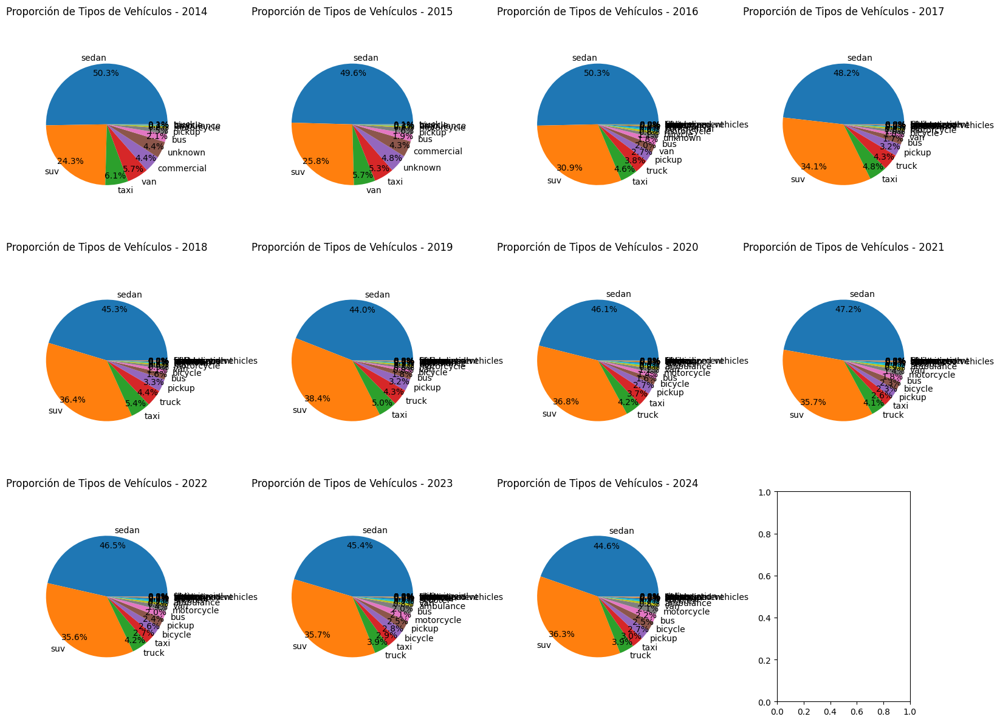

In [ ]:
# Crear un gráfico de pastel para cada año usando el diccionario dfPorYear
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

# Iterar sobre los años y crear un gráfico de pastel para cada uno
for i, (year, df_year) in enumerate(dfPorYear.items()):
    # Contar la cantidad de accidentes por tipo de vehículo
    vehicle_counts = df_year['Tipo vehículo'].value_counts()

    # Graficar el pastel
    axes[i].pie(vehicle_counts, labels=vehicle_counts.index, autopct='%1.1f%%', startangle=0, pctdistance=0.85)

    # Configuración del título y aspecto
    axes[i].set_title(f'Proporción de Tipos de Vehículos - {year}')
    axes[i].axis('equal')  # Para que el gráfico sea circular

# Ajustar el diseño
plt.tight_layout()

# Mostrar el gráfico
plt.show()

En estos gráficos de pastel analizamos la proporción en la que aparecen diferentes tipos de vehículos en accidentes automovilísticos en cada año, desde 2014 hasta 2024. Estos datos proporcionan una visión clara de cómo ciertos tipos de vehículos tienen una mayor participación de los accidentes.

1. Predominio del "Sedan" y el "SUV"
*	Sedan:
Este tipo de vehículo es consistentemente el más involucrado en accidentes en todos los años analizados. Su proporción varía ligeramente, pero siempre se mantiene alrededor del 44%-50% del total de accidentes. Esto podría deberse a que el sedan es uno de los vehículos más comunes en la ciudad de New York.
*	SUV:
Los SUVs ocupan el segundo lugar en participación, con proporciones que oscilan entre el 24% y 38% según el año. Hay una tendencia al aumento de su participación, particularmente en los años 2016-2019, lo cual podría estar relacionado con un incremento en la popularidad de estos vehículos en el mercado.

2. Participación de Otros Tipos de Vehículos
*	Taxi:
Los taxis presentan una proporción estable, alrededor del 4%-6% en la mayoría de los años. Esto sugiere que, aunque no son tan numerosos como los sedanes o SUVs, están relativamente presentes en accidentes, probablemente debido a su alta exposición al tráfico por su constante operación.
*	Van y comerciales:
Estos tipos de vehículos muestran proporciones menores, generalmente por debajo del 6%. Su participación estable podría explicarse por su rol específico en transporte de carga o pasajeros.
*	Pickups, buses y motocicletas:
Estos tipos de vehículos tienen proporciones bajas, con valores típicamente menores al 5%.

3. Cambios a lo Largo del Tiempo
*	Entre 2014 y 2024, hay una ligera reducción en la proporción de accidentes involucrando sedanes (de más del 50% en 2014 a cerca del 44%-47% en 2024). Esto podría estar relacionado con una mayor diversificación en los tipos de vehículos utilizados por las personas, especialmente el aumento de SUVs.
*	Por el contrario, los SUVs han aumentado gradualmente su proporción, reflejando un cambio en las preferencias del consumidor hacia este tipo de vehículo.

4. Factores Contextuales
*	Mayor uso del sedan:
El predominio de los sedanes podría estar vinculado a su popularidad como vehículos familiares y urbanos, donde hay mayor densidad de tráfico y, por ende, más posibilidades de accidentes.
*	Incremento de SUVs:
La mayor participación de SUVs podría relacionarse con su creciente uso, pero también con ciertos riesgos asociados, como su mayor peso y dimensiones que afectan la maniobrabilidad.

Conclusión

Este análisis refleja cómo los sedanes y SUVs son los vehículos más involucrados en accidentes debido a su popularidad y presencia en la ciudad. Sin embargo, también se observa que hay cambios en la proporción de estos tipos de vehículos, lo que podría estar influenciado por tendencias del mercado y cambios en las preferencias de los conductores. Estos datos podrían ser útiles para implementar estrategias de seguridad vial específicas, dirigidas a los vehículos más accidentados.


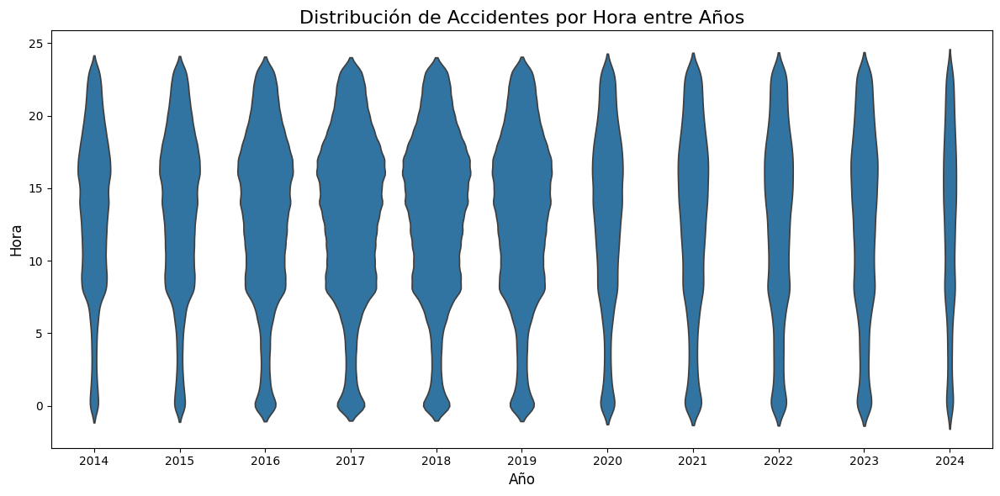

In [ ]:
# Crear una lista para almacenar las horas y los años correspondientes
horas = []
años = []

# Llenar las listas con las horas y los años
for year, df_year in dfPorYear.items():
    horas += df_year['Hora'].tolist()  # Agregar las horas
    años += [year] * len(df_year)  # Agregar el año correspondiente

# Crear un DataFrame con las horas y los años
df_horas = pd.DataFrame({'Hora': horas, 'Año': años})

# Crear el gráfico de violín
plt.figure(figsize=(12, 6))
sns.violinplot(x='Año', y='Hora', data=df_horas, inner=None, density_norm='count')

# Personalizar el gráfico
plt.title('Distribución de Accidentes por Hora entre Años', fontsize=16)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Hora', fontsize=12)

# Ajustar el diseño
plt.tight_layout()

# Mostrar el gráfico
plt.show()

Este gráfico de densidad nos muestra la distribución de accidentes por hora de los años 2014 a 2024. Cada "violín" representa la frecuencia de los accidentes durante el día para cada año. A continuación, se presentará el análisis realizado:

1. Patrones Generales
*	Horas pico (7-9 a.m. y 5-7 p.m.):
La densidad de accidentes es mayor en estas horas, lo cual es esperado, dado que estas horas coinciden con los horarios de mayor movilización debido a los desplazamientos laborales y escolares. Esto es consistente en todos los años.
*	Madrugada (12-5 a.m.):
La densidad de accidentes es menor a estas horas, lo que puede ser dado por la baja actividad en horas de la madrugada. Sin embargo, los accidentes en este horario podrían estar asociados con conductores bajo efectos del alcohol.
*	Mediodía (11 a.m.-1 p.m.):
Aunque hay un aumento de densidad, es menor comparado con las horas pico. Esto puede deberse a un tráfico reducido, como actividades comerciales.

2. Cambios en la Densidad a lo Largo de los Años
*	Estabilidad:
No hay cambios significativos en la forma de las distribuciones de un año a otro, lo único a resaltar es una disminución en la densidad anual a partir del año 2019. Esto indica que los patrones horarios de accidentes han permanecido relativamente constantes en el tiempo.
*	2020 y 2021 (Pandemia):
Durante estos años, se observa una reducción en la densidad general, particularmente en las horas pico. Esto puede estar relacionado con las restricciones de movilidad y el aumento del trabajo remoto debido a la pandemia de COVID-19.

Conclusión
Este análisis nos confirma que los accidentes de tráfico están relacionados con la forma en que las personas se movilizan durante el día. Las estrategias de prevención deben centrarse en las horas pico y atender también riesgos nocturnos.

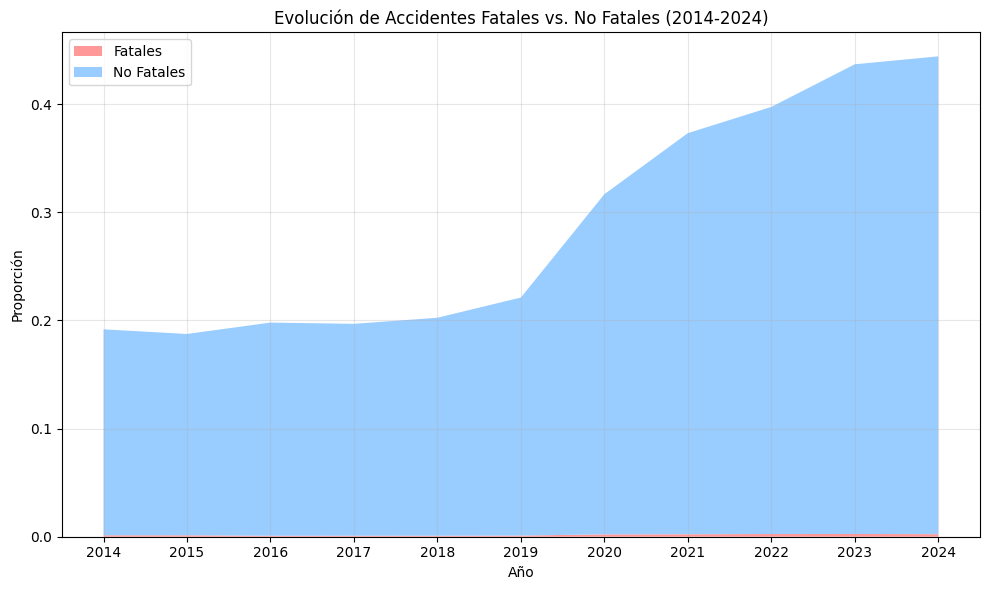

In [ ]:
# Crear un DataFrame para almacenar la proporción de accidentes fatales y no fatales por año
proporciones = []

for year, df in dfPorYear.items():
    total_accidentes = len(df)
    fatales = len(df[df['Personas fallecidas'] > 0])
    no_fatales = len(df[df['Personas heridas'] > 0])

    proporciones.append({
        'Año': year,
        'Fatales': fatales / total_accidentes if total_accidentes > 0 else 0,
        'No Fatales': no_fatales / total_accidentes if total_accidentes > 0 else 0
    })

# Convertir a DataFrame
df_proporciones = pd.DataFrame(proporciones)

# Crear el gráfico de áreas apiladas
plt.figure(figsize=(10, 6))
plt.stackplot(
    df_proporciones['Año'],
    df_proporciones['Fatales'],
    df_proporciones['No Fatales'],
    labels=['Fatales', 'No Fatales'],
    colors=['#FF9999', '#99CCFF']
)

plt.title('Evolución de Accidentes Fatales vs. No Fatales (2014-2024)')
plt.xlabel('Año')
plt.ylabel('Proporción')
plt.legend(loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

Análisis Alternativo de la Evolución de Accidentes Fatales vs. No Fatales (2014-2024)

Este gráfico muestra la proporción de accidentes clasificados como fatales y no fatales a lo largo de los años. A continuación, se realiza un análisis de este.

1. Accidentes Fatales: Un Componente Muy Reducido

*	Proporción Insignificante:
Los accidentes fatales representan una proporción muy pequeña, casi imperceptible en el gráfico. Esto sugiere que, son eventos que muy rara vez ocurren en comparación con el total de accidentes.
*	Tendencia al Incremento:
A partir de 2019, hay un gran aumento en la proporción de accidentes en donde se encuentren heridos o muertos, lo cual podría reflejar:
  *	Mayor número de incidentes de alta gravedad.
  *	Cambios en los patrones de manejo ( velocidad excesiva o distracciones, posiblemente influenciadas por la pandemia).

2. Accidentes con Heridos: Crecimiento Notable Desde 2019

*	Estabilidad Inicial (2014-2019):
Durante el periodo 2014-2019, los accidentes con heridos representaban aproximadamente el 20% de los casos. Esto indica que la mayoría de los accidentes eran de bajo impacto o sin consecuencias graves para los involucrados.
*	Incremento Progresivo (2019-2024):
Desde 2019, la proporción de accidentes con heridos ha aumentado de manera notable, acercándose al 40% en 2024. Este comportamiento podría deberse a varios factores:
  *	Cambios en el tráfico: Incremento en el número de vehículos en circulación tras la pandemia.
  *	Mayor reporte de accidentes: Un mejor registro de accidentes, incluyendo aquellos con lesiones menores.
  *	Factores de riesgo: Incremento en conductas peligrosas como el uso del celular mientras se conduce.

3. Accidentes Sin Heridos: Un Componente Dominante pero Variable

*	Proporción Mayoritaria:
A lo largo de todo el período, los accidentes no fatales y sin heridos constituyen la mayor parte de los incidentes.
*	Tendencia Creciente (2019-2024):
Se puede notar un gran incremento en la proporción de accidentes con heridos después del año 2019, viendo estos resultados y analizando las anteriores graficas podemos deducir que aunque hay una disminución en el número de accidentes después de la pandemia ocurrió un aumento significativo en la cantidad de veces en los que estos accidentes producen heridas.

4. Relación Temporal y Factores Contextuales

*	Cambios en 2019:
Tanto los accidentes fatales como los que incluyen heridos comenzaron a crecer significativamente en este año. Esto podría coincidir con:
  *	Cambios en las condiciones del tráfico.
  *	Mayor exposición a factores de riesgo, como distracciones o conductas imprudentes.
*	Impacto de la Pandemia (2020-2021):
Durante la pandemia, aunque hubo una reducción en la cantidad total de tráfico, aquellos que permanecieron en las carreteras pueden haber conducido a velocidades más altas, incrementando la severidad de los accidentes.

5. Consideraciones para la Seguridad Vial

*	Foco en los Accidentes con Heridos:
Dado que representan una proporción creciente, las estrategias deben enfocarse en reducir estos casos mediante:
  *	Mejora de la infraestructura vial para minimizar colisiones.
  *	Implementación de campañas educativas sobre manejo.
  *	Fomento del uso de dispositivos de seguridad.
*	Prevención de Accidentes Fatales:
Aunque son una minoría, los accidentes fatales pueden abordarse con medidas específicas, como:
*	Reducción de velocidad en zonas de alto riesgo.
*	Controles más estrictos sobre consumo de alcohol y sustancias mientras se conduce.

Conclusión

El gráfico revela que, aunque los accidentes fatales son mínimos, existe una tendencia preocupante de crecimiento tanto en estos como en los accidentes con heridos desde 2019. Esto subraya la importancia de tomar medidas para mejorar la seguridad vial, especialmente mediante la mitigación de factores que aumentan la severidad de los incidentes


In [ ]:
# Combinar los DataFrames de todos los años en un solo DataFrame
df_combined = pd.concat(dfPorYear.values(), ignore_index=True)

# Crear el mapa centrado en las coordenadas promedio
heatmap = folium.Map(
    location=[df_combined['Latitud'].mean(), df_combined['Longitud'].mean()],
    zoom_start=10
)

# Preparar los datos para el HeatMap (latitud y longitud)
heat_data = df_combined[['Latitud', 'Longitud']].dropna().values.tolist()

# Añadir los puntos al mapa como un mapa de calor
HeatMap(    heat_data,
    radius=15,           # Aumentar el radio para abarcar más área
    blur=10,             # Reducir el desenfoque para más detalle
    max_zoom=1,          # Mantener el zoom máximo para densidad
    min_opacity=0.5,     # Aumentar la opacidad mínima para destacar áreas menos densas
    gradient={           # Personalizar los colores del mapa
        0.2: 'blue',
        0.5: 'lime',
        0.8: 'orange',
        1: 'red'
         }).add_to(heatmap)

# Mostrar el mapa en Google Colab
heatmap

En este mapa de calor se representa la distribución geográfica de los accidentes ocurridos en la ciudad de Ney York  desde el año 2014 hasta el 2024. A continuación, se mostrara un análisis sobre los datos dados por el mapa de calor

1. Áreas de Máxima Intensidad
*	Región Metropolitana de Nueva York:
Esta zona se destaca como el lugar con mayor concentración de accidentes. Dentro de esta región está:
*	Manhattan y Brooklyn: Muestran las mayores intensidades de calor, esto puede deberse a:
  *	Alta densidad de población y vehículos.
  *	Gran cantidad de intersecciones y tráfico constante, como se puede notar en Midtown west, donde se encuentra la zona con mayor accidentalidad de New York.
  *	Mayor actividad turística, comercial y laboral, ya que en este sitio se encuentran lugares como el Empire State, sitio frecuentado por turistas, por lo tanto, un lugar donde habrá mucho tráfico vehicular.
  *	Queens: También muestra una notable intensidad, aunque menor que Manhattan y Brooklyn.
*	Zonas Periféricas de Long Island:
Aunque no tienen la misma densidad de accidentes que Nueva York, ciertas áreas cercanas a la costa oeste de Long Island presentan una considerable intensidad de accidentes. Esto puede estar relacionado con:
  *	Carreteras principales que conectan la región con la ciudad.
  *	Movimientos diarios de tráfico entre áreas suburbanas y urbanas.

2. Conexiones Regionales
*	Nueva Jersey (Área de Newark):
Esta región muestra un aumento en la intensidad, lo que indica que las carreteras principales que conectan Newark y Nueva York tienen un cantidad no despreciable de accidentes. unas posibles causas pueden ser:
  *	Tráfico pesado en las autopistas.
  *	Alta densidad de conductores que se mueven entre estados.
*	Puentes y Túneles:
Las áreas cercanas a los principales accesos a Manhattan, como el Puente George Washington y el Túnel Lincoln, parecen ser puntos críticos para los accidentes. Esto es relacionado con el alto volumen de tráfico que pasa por estos lugares de forma diaria.
*	Zonas con poca intensidad:
Zonas como áreas rurales al norte y al este de Long Island, muestran una menor densidad de accidentes. Esto puede deberse a una falta de interés de turistas y ciudadanos a ir a estas zonas, ya sea porque se encuentran lejos de lugares más turisticos o porque no tienen cosas que sean de interes general para las personas que visitan esta ciudad.


Conclusión

El mapa de calor refleja que los accidentes se concentran en áreas urbanas densamente pobladas, como Nueva York, con epicentros secundarios en Newark y Long Island. Esto sugiere que los esfuerzos en seguridad vial deben priorizar las zonas de alta densidad y con grandes intersecciones para evitar más accidentes en estos puntos críticos de la ciudad.

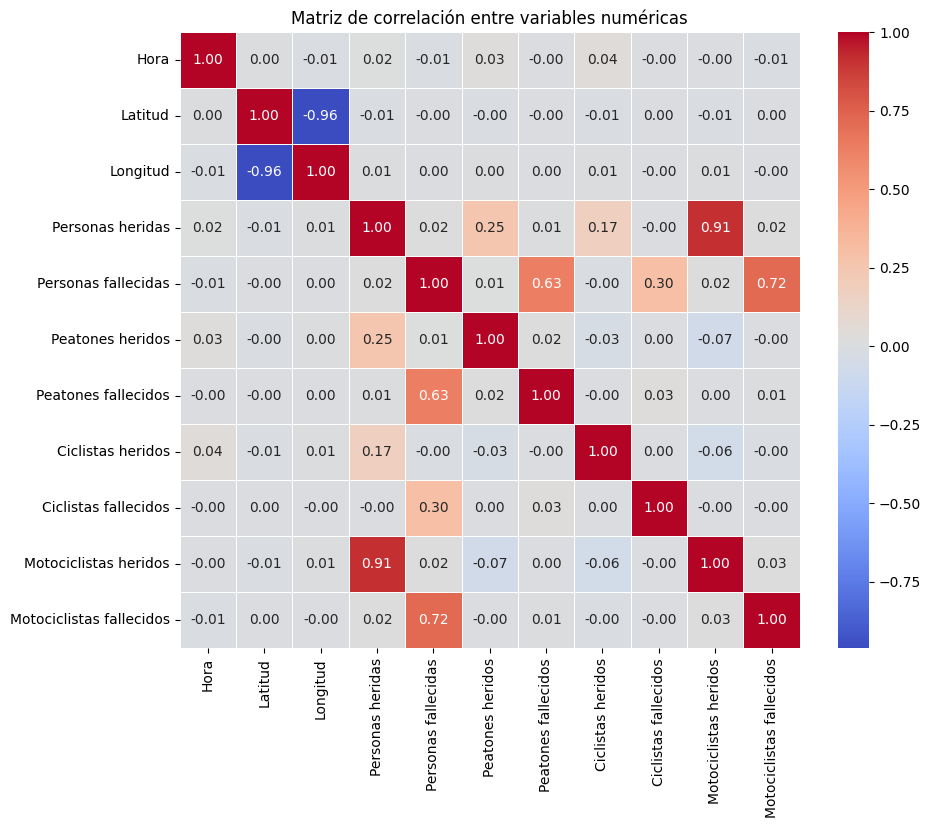

In [ ]:
# Seleccionar solo las columnas numéricas
df_numeric = dfClear.select_dtypes(include=['number'])

# Calcular la matriz de correlación
correlation_matrix = df_numeric.corr()

# Configurar el tamaño del gráfico
plt.figure(figsize=(10, 8))

# Crear el mapa de calor
sns.heatmap(
    correlation_matrix,
    annot=True,  # Mostrar valores en el gráfico
    fmt=".2f",   # Formato de los números
    cmap="coolwarm",  # Colores
    linewidths=0.5,  # Líneas entre celdas
)

# Añadir título
plt.title("Matriz de correlación entre variables numéricas")
plt.show()

La matriz de correlación muestra las relaciones entre distintas variables del conjunto de datos, las cuales estan relacionadas con accidentes de tránsito en la ciudad de New York. A continuación, analizaremos algunos aspectos clave:

1. Correlaciones más altas y significativas:
*	Latitud y Longitud (-0.96):
  *	Hay una relación muy fuerte y negativa entre estas dos variables, lo que significa que los accidentes tienden a ocurrir en lugares específicos.
* Personas heridas y Motociclistas heridos (0.91):
  *	Existe una alta relación positiva, lo cual sugiere que un gran número de accidentes con víctimas incluye motociclistas.
*	Personas fallecidas y Motociclistas fallecidos (0.72):
  *	Este dato confirma que un gran porcentaje de los fallecimientos en accidentes involucra motociclistas.

2. Correlaciones medianamente altas:
*	Peatones heridos y Personas heridas (0.25):
  *	Aunque no es tan alta, esta correlación indica que los peatones forman una parte importante del total de personas heridas en accidentes.
*	Peatones fallecidos y Personas fallecidas (0.63):
  *	Una correlación moderada indica que los peatones también representan una proporción significativa de los fallecimientos en accidentes.
*	Ciclistas heridos y Personas heridas (0.17):
  *	Aunque es más baja que con los motociclistas y peatones, esta correlación destaca a los ciclistas como otro grupo vulnerable.

3. Correlaciones bajas o insignificantes
*	Hora con otras variables:
  * no hay correlación significativa entre la hora del día y las demás variables, lo que indica que las variables representadas en esta matriz de correlación no muestran una relación directa con la hora del día.
*	Ciclistas fallecidos y otras variables:
  *	Las correlaciones son bastante bajas, lo que puede deberse a un menor número de ciclistas en nuestro conjunto de datos en comparación con peatones y motociclistas.

4. Interpretaciones Clave
*	Motociclistas como grupo vulnerable:
  *	Las altas correlaciones entre motociclistas heridos/fallecidos y el total de personas afectadas resaltan la necesidad de intervenciones dirigidas específicamente a este grupo que tienen un alto riesgo en los accidentes.
*	Peatones en riesgo:
  *	Las correlaciones moderadas entre peatones y los totales de heridos/fallecidos sugieren que los peatones, especialmente en áreas urbanas, son un grupo a tener en cuenta en un accidente por su posibilidad de resultar heridos.
*	Distribución geográfica:
  *	La fuerte relación entre latitud y longitud muestra que los accidentes están concentrados en ciertas áreas geográficas específicas. Esto con el mapa de calor podemos identificar las ubicaciones exactas.

Conclusión
La matriz de correlación proporciona información valiosa para identificar grupos vulnerables (motociclistas y peatones) y patrones geográficos claros. Esto permite diseñar estrategias específicas para reducir accidentes y mejorar la seguridad vial en las áreas más afectadas.


# Prueba de hipótesis

| Año  | Colisiones | Muertes | Proporción (Muertes/Colisiones) |
|------|------------|---------|---------------------------------|
| 2024 | 84,069     | 244     | 0.0029023                       |
| 2023 | 89,833     | 249     | 0.0027718                       |

Tomado de: [Excel accidentes NYPD](https://www.nyc.gov/assets/nypd/downloads/excel/traffic_data/traffic-statistics/ts-en-us-Citywide.xlsx )

Proporción promedio: 0.002837

Estadístico z: -0.7585919682782196
p-value: 0.44809667873691084
No se puede rechazar la hipótesis nula: La proporción de accidentes fatales no es significativamente diferente a la proporción promedio.


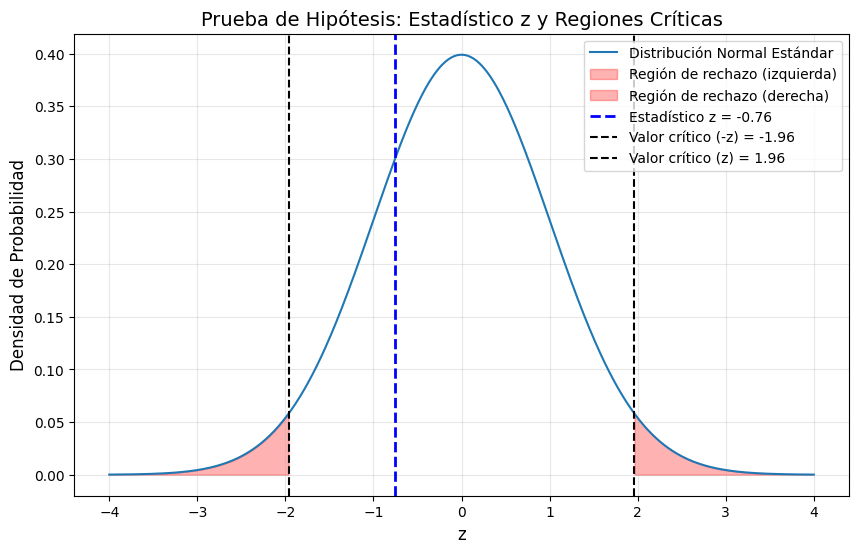

In [ ]:
# Extraer datos para 2019
data = dfPorYear['2023']
total_colisiones_2019 = len(data)
total_muertes_2019 = data['Personas fallecidas'].sum()

# Proporción esperada
p_0 = 0.002837

# Prueba de hipótesis
stat, p_value = proportions_ztest(total_muertes_2019, total_colisiones_2019, value=p_0)

print("Estadístico z:", stat)
print("p-value:", p_value)

# Interpretación
alpha = 0.05
if p_value < alpha:
    print("Rechazamos la hipótesis nula: La proporción de accidentes fatales es significativamente diferente a la proporción promedio.")
else:
    print("No se puede rechazar la hipótesis nula: La proporción de accidentes fatales no es significativamente diferente a la proporción promedio.")

graficarHipotesis(alpha, stat)

Esta prueba de hiporesis esta dada para determinar si la proporción de accidentes fatales en 2019 es significativamente diferente de la proporción promedio (0.00287718).

Información clave:
1.	Hipótesis:
*	H₀ (Hipótesis nula): La proporción de accidentes fatales en 2019 es igual a la proporción promedio (0.00287718).
*	H₁ (Hipótesis alternativa): La proporción de accidentes fatales en 2019 es diferente a la proporción promedio.
2.	Nivel de significancia (α): 0.05.
3.	Resultados del test estadístico:
*	Estadístico z: -0.76.
*	p-valor: 0.4488, que es mayor al nivel de significancia.
4.	Valores críticos:
*	Límites para rechazo: ±1.96.

Interpretación de la gráfica:
*	Distribución normal estándar:
  *	Representada por la curva azul.
*	Región de rechazo:
  *	Las áreas en rojo a ambos extremos (z < -1.96 o z > 1.96) indican las regiones donde se rechaza la hipótesis nula.
*	Estadístico z calculado (línea azul):
  *	El valor de z (-0.76) cae dentro de la región de aceptación.

Conclusión:
Se acepta la hipótesis nula, ya que el estadístico z no está en la región de rechazo. Esto indica que la proporción de accidentes fatales en 2019 no es significativamente diferente de la proporción promedio. Esto indica que ese año no tuvo un cambio significativo con respecto a los anteriores. Este resultado indica una estabilidad en la proporción de accidentes fatales durante el período analizado.


| Año  | Colisiones | Heridos | Proporción (Heridos/Colisiones) |
|------|------------|---------|---------------------------------|
| 2024 | 84,069     | 50.003  | 0.594785                        |
| 2023 | 89,833     | 50.563  | 0.562855                        |

Tomado de: [Excel accidentes NYPD](https://www.nyc.gov/assets/nypd/downloads/excel/traffic_data/traffic-statistics/ts-en-us-Citywide.xlsx )

Proporción promedio: 0.578820

Estadístico z: 8.475710230415176
p-value: 2.3364966679989293e-17
Rechazamos la hipótesis nula: La proporción de accidentes fatales es significativamente diferente a la proporción promedio.


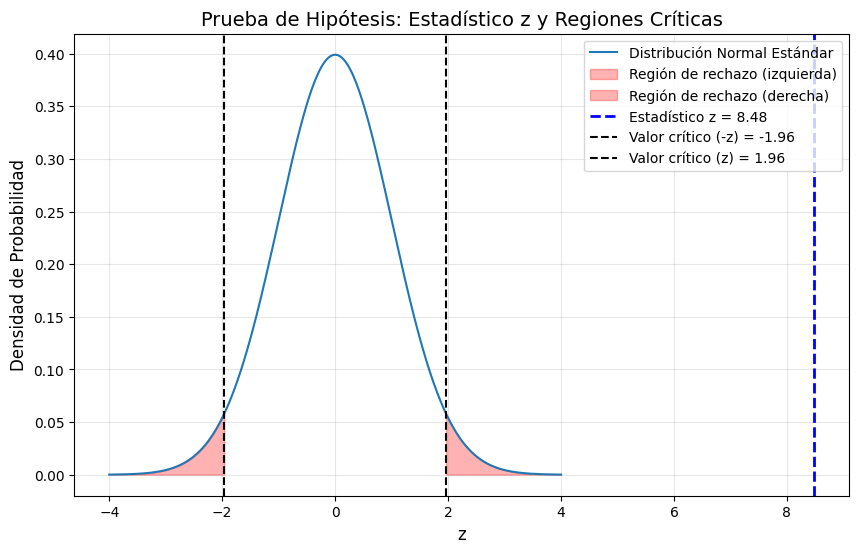

In [ ]:
# Extraer datos para 2019
data = dfPorYear['2024']
total_colisiones_2019 = len(data)
total_muertes_2019 = data['Personas heridas'].sum()

# Proporción esperada
p_0 = 0.578820

# Prueba de hipótesis
stat, p_value = proportions_ztest(total_muertes_2019, total_colisiones_2019, value=p_0)

print("Estadístico z:", stat)
print("p-value:", p_value)

# Interpretación
alpha = 0.05
if p_value < alpha:
    print("Rechazamos la hipótesis nula: La proporción de accidentes fatales es significativamente diferente a la proporción promedio.")
else:
    print("No se puede rechazar la hipótesis nula: La proporción de accidentes fatales no es significativamente diferente a la proporción promedio.")

graficarHipotesis(alpha, stat)



En esta gráfica se muestra una prueba de hipótesis para proporciones utilizando un contraste de dos colas. A continuación, vamos a explicar los datos, la gráfica y a analizarla:
Información clave de la prueba:
1.	Hipótesis nula (H₀):
  *	La proporción de accidentes con heridos es igual a la proporción promedio (0.57882).
2.	Hipótesis alternativa (H₁):
  *	La proporción de accidentes con heridos es diferente de la proporción promedio.
3.	Nivel de significancia (α):
  *	0.05.
4.	Estadístico z:
  *	Valor calculado: 8.08.
  *	Z crítico: ±1.96 (valores que delimitan las regiones de rechazo).
5.	p-valor:
  *	2.33e-15, que es significativamente menor a 0.05.

Interpretación de la gráfica:
*	Distribución normal estándar:
  *	Representada por la curva azul.
*	Región de rechazo:
  *	Las áreas en rojo indican los valores extremos (z < -1.96 o z > 1.96). Si el estadístico z cae en estas regiones, se rechaza la hipótesis nula.
*	Estadístico z calculado (línea azul):
  *	El valor de z = 8.08 se encuentra en una zona de rechazo, por lo tanto, se rechaza la hipótesis nula.

Conclusión
Se rechaza la hipótesis nula, ya que el valor z está fuera del rango crítico, esto quiere decir que la proporción de accidentes de heridos en 2019 es diferente de la proporción promedio de los datos.



## Prueba de normalidad

Probar si las personas heridas cumplen un comportamiento normal

Estadístico W: 0.6308, p-valor: 0.0000

Shapiro-Wilk Test:
Los datos NO tienen una distribución normal.

Gráfico Q-Q Test:


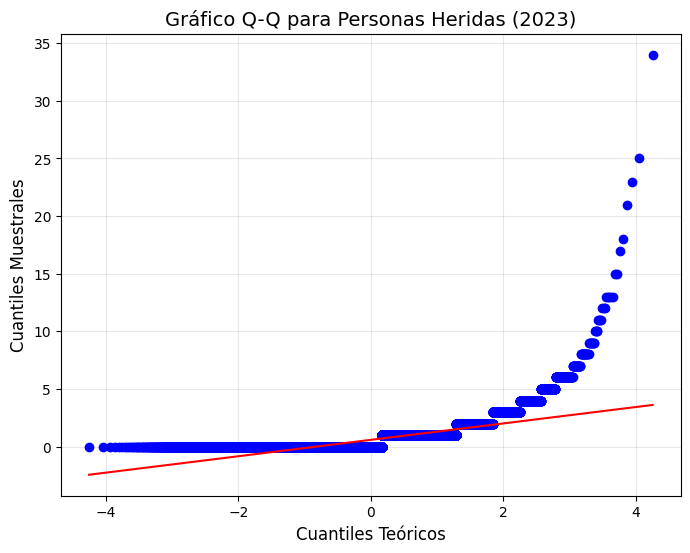

In [ ]:
# Seleccionar los datos de la columna 'Personas heridas'
data = dfPorYear['2023']['Personas heridas']

# Revisar por Shapiro-Wilk Test
stat, p_value = stats.shapiro(data)
print(f'Estadístico W: {stat:.4f}, p-valor: {p_value:.4f}')

print(f"\nShapiro-Wilk Test:")
if p_value > 0.05:
    print("Los datos tienen una distribución normal.")
else:
    print("Los datos NO tienen una distribución normal.")


print(f"\nGráfico Q-Q Test:")
# Crear el gráfico Q-Q
plt.figure(figsize=(8, 6))
stats.probplot(data, dist="norm", plot=plt)

# Personalización del gráfico
plt.title('Gráfico Q-Q para Personas Heridas (2023)', fontsize=14)
plt.xlabel('Cuantiles Teóricos', fontsize=12)
plt.ylabel('Cuantiles Muestrales', fontsize=12)
plt.grid(alpha=0.3)
plt.show()

Este es un Gráfico Q-Q (Quantile-Quantile), el cual en pocas palabras nos ayuda a comparar el comportamiento de una distribución normal con el comportamiento de nuestros datos, para ver si siguen un comportamiento normal. A continuación, el análisis:
1.	Resultado del Test de Shapiro-Wilk:
*	Estadístico: 0.6388
*	p-valor: 0.0000
*	Interpretación: El p-valor es menor a 0.05, por lo que se rechaza la hipótesis nula de que los datos siguen una distribución normal. Esto nos indica que los datos de las personas heridas en 2023 no tienen un comportamiento normal.
2.	Interpretación de la Gráfica Q-Q:
*	Línea Roja: Representa la distribución normal teórica (como debería comportarse para que siga una distribución normal).
*	Puntos Azules: Son los cuantiles de los datos observados.
*	Desviaciones Marcadas: Los puntos se desvían de la línea roja, especialmente en los extremos. Esto confirma que los datos no siguen una distribución normal, ya que hay una mayor concentración en valores extremos o atípicos.
3.	Conclusión:
Los datos de personas heridas en 2023 presentan un comportamiento que no sigue un comportamiento normal.

# **Limitaciones y posibles mejoras**

# Limitaciones:
* Uso de datos viejos
  * Como se pudo observar en las graficas al usar datos que no sean actualizados nuestro analisis pierde credibilidad, ya que por lo visto no se puede reflejar las condiciones actuales de los accidentes, como se vio con la pandemia, que fue un antes y un despues en los accidentes, por lo tanto una constante actualizacion es necesaria para este proyecto.

* Veracidad de datos:
  *	Si los datos utilizados son incompletos o tienen errores (como valores atípicos, omisiones, o registros mal ingresados), los análisis pueden no reflejar la realidad que vive la ciudad de New York.
  *	Necesidad de uso de fuentes externas, como bases de datos del NYPD, Esto implica que la validez del proyecto se ve influenciada por factores externos, teniendo en cuenta que dependemos de la validez de datos externos.

* Accesibilidad de Resultados:
  * Los resultados actuales pueden no ser faciles de interpretar para usuarios no técnicos debido a gráficos y terminología estadística, aun habiendo explicado cada parte.
  * No hay forma de mostrar los analisis que se hicieron a la ciudad de New York, la cual seria la que más se beneficiaria de estos.

# Posibles mejoras:
* Evaluar el Impacto Social de este estudio en el transito:
  *	Relacionar los resultados del análisis con campañas de prevención de accidentes y educación vial, teniendo en cuenta que sabemos partes vulnerables y el aumento en la proporcion de heridos en la accidentalidad.
  * Estudiar el impacto de políticas públicas previas sobre la seguridad vial.

*	Mejoras en los Datos:
  *	mejorar el datase, incluyendo información adicional como condiciones climáticas, uso de cinturones de seguridad, fallos en el vehiculo, etc. teniendo estos datos extra ayudaria a una mejora en la comprension de los accidentes automovilistocos
  *	Implementar un mejor sistema para limpiar y eliminar errores y valores atípicos en los datos.


# **Referencias Bibliograficas**

Motor vehicle collisions - crashes: USA. (2024, 10 julio). Kaggle. https://www.kaggle.com/datasets/sahityasetu/motor-vehicle-collisions-crashes-usa

\\

Diario, E. (2022, 24 septiembre). Muertes por accidentes de tránsito en Nueva York incrementaron un 35% en lo que va de 2022. El Diario NY. https://eldiariony.com/2022/04/12/muertes-por-accidentes-de-transito-en-nueva-york-incrementaron-un-35-en-lo-que-va-de-2022/

\\

Traffic Data - TrafficStat - NYPD. (s. f.). https://www.nyc.gov/assets/nypd/downloads/excel/traffic_data/traffic-statistics/ts-en-us-Citywide.xlsx

\\

